In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
import numpy as np

Mounted at /content/drive


In [2]:
!bash /content/drive/MyDrive/V2_drift/texturemodel/code/run/fit_cross_session_matrix_fast.sh

Streaming output truncated to the last 5000 lines.
No voxels have this pRF saved as their best model, skipping it.

Processing prf 574 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 575 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 576 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 577 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 578 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 579 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 580 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 581 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 582 of 1456
Index into batch for prf 582: 82
Final size of feature matrix for this image set and pRF is:
(1500, 18)
Hello there,  (75

In [ ]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

2.11.0+cu128
True
Tesla T4


In [ ]:
from pathlib import Path
import h5py
import numpy as np

FILE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/"
    "S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py"
)

print(FILE)
print("Exists:", FILE.exists())


def inspect(name, obj):
    if isinstance(obj, h5py.Group):
        print(f"\nGROUP: {name}")
        return

    arr = obj[...]

    print(f"\nDATASET: {name}")
    print(f"  shape : {arr.shape}")
    print(f"  dtype : {arr.dtype}")

    if np.issubdtype(arr.dtype, np.number):
        print(f"  min   : {np.nanmin(arr)}")
        print(f"  max   : {np.nanmax(arr)}")
        print(f"  mean  : {np.nanmean(arr)}")
        print(f"  std   : {np.nanstd(arr)}")
        print(f"  NaN   : {np.isnan(arr).sum()}")
        print(f"  Inf   : {np.isinf(arr).sum()}")

    if len(obj.attrs):
        print("  attrs:")
        for k, v in obj.attrs.items():
            print(f"    {k}: {v}")


with h5py.File(FILE, "r") as f:

    print("\n================ FILE STRUCTURE ================\n")

    f.visititems(inspect)

    print("\n================ ROOT ATTRIBUTES ================\n")

    for k, v in f.attrs.items():
        print(k, ":", v)

/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
Exists: True

================ FILE STRUCTURE ================


DATASET: best_biases
  shape : (30, 1433, 1)
  dtype : float32
  min   : -12219.0283203125
  max   : 11761.7314453125
  mean  : 517.2416381835938
  std   : 820.5936279296875
  NaN   : 0
  Inf   : 0

DATASET: best_lambdas
  shape : (30, 1433, 1)
  dtype : int32
  min   : 0
  max   : 0
  mean  : 0.0
  std   : 0.0
  NaN   : 0
  Inf   : 0

DATASET: best_losses
  shape : (30, 1433, 1)
  dtype : float32
  min   : 13018296.0
  max   : 80031113216.0
  mean  : 302377888.0
  std   : 1011333312.0
  NaN   : 0
  Inf   : 0

DATASET: best_prf_models
  shape : (30, 1433, 1)
  dtype : int32
  min   : 0
  max   : 1274
  mean  : 351.04884856943477
  std   : 277.2917154379544
  NaN   : 0
  Inf   : 0

DATASET: best_weights
  shape : (30, 1433, 54, 1)
  dtype : float32
  m

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01")

for p in sorted(root.iterdir()):
    print(p.name)

texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca40_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca60_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca80_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca90_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca95_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V2_pca40_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V2_pca60_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V2_pca80_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V2_pca90_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V2_pca95_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V3_pca40_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V3_pca60_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V3_pca80_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V3_pca90_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_V3_pca95_use_nsd_grid5_pRFs
texture_pyramid_OLS_4ori_4sf_pcaAll_hV4_

In [ ]:
import numpy as np
import nibabel as nib
from pathlib import Path

# -----------------------------
# Subject and paths
# -----------------------------
SUBJECT = 1

NSD_BASE = "/content/drive/MyDrive/V1_Drift/NSD"

file = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_session_9_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_validated_on_session_30/"
    "Jul-29-2026_2036_14/"
    "all_fit_params.npy"
)

visual_rois_path = (
    f"{NSD_BASE}/subj{SUBJECT:02d}/func1pt8mm/roi/"
    "prf-visualrois.nii.gz"
)

# -----------------------------
# Load fitted parameters
# -----------------------------
params = np.load(file, allow_pickle=True).item()

print("Loaded fit file:")
print(file)
print("\nAvailable keys:")
print(params.keys())

# -----------------------------
# Load pRF ROI labels
# -----------------------------
prf_labels = (
    nib.load(visual_rois_path)
    .get_fdata()
    .reshape(-1)
)

# Count every ROI label
values, counts = np.unique(prf_labels, return_counts=True)

print("\nROI label counts:")
for value, count in zip(values, counts):
    print(f"Label {int(value):2d}: {count}")

# -----------------------------
# Define pRF V1
# Labels 1 and 2 are V1v and V1d
# -----------------------------
prf_v1_mask = np.isin(prf_labels, [1, 2])

# -----------------------------
# Extract fitted voxel indices
# -----------------------------
voxel_idx = (
    np.asarray(params["voxel_index"])
    .squeeze()
    .astype(int)
)

# Sanity checks
assert voxel_idx.ndim == 1, (
    f"Expected voxel_idx to be one-dimensional, got {voxel_idx.shape}"
)

assert voxel_idx.min() >= 0, (
    f"Found a negative voxel index: {voxel_idx.min()}"
)

assert voxel_idx.max() < prf_labels.size, (
    f"Maximum voxel index {voxel_idx.max()} exceeds "
    f"NIfTI size {prf_labels.size}"
)

# -----------------------------
# Identify fitted voxels inside pRF V1
# -----------------------------
inside_prf_v1 = prf_v1_mask[voxel_idx]

print("\n--------------------------------")
print(f"Total voxels in pRF V1:       {prf_v1_mask.sum()}")
print(f"Total fitted TS voxels:       {voxel_idx.size}")
print(f"TS voxels inside pRF V1:      {inside_prf_v1.sum()}")
print(f"TS voxels outside pRF V1:     {(~inside_prf_v1).sum()}")

print("\nSanity checks:")
print(f"NIfTI flattened size:         {prf_labels.size}")
print(f"Minimum fitted voxel index:   {voxel_idx.min()}")
print(f"Maximum fitted voxel index:   {voxel_idx.max()}")

Loaded fit file:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_session_9_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_validated_on_session_30/Jul-29-2026_2036_14/all_fit_params.npy

Available keys:
dict_keys(['subject', 'volume_space', 'roi_name', 'pca_pct_var', 'fitting_types', 'voxel_mask', 'average_image_reps', 'brain_nii_shape', 'image_order', 'voxel_index', 'voxel_roi', 'voxel_ncsnr', 'which_prf_grid', 'prfs_fixed_sigma', 'models', 'best_losses', 'best_lambdas', 'best_params', 'lambdas', 'val_cc', 'val_r2', 'debug_y_true', 'debug_y_pred', 'debug_bad_voxels', 'partial_masks', 'partial_version_names', 'zscore_features', 'ridge', 'set_lambda_per_group', 'debug', 'up_to_sess', 'single_sess', 'single_val_sess', 'whole_session_split', 'use_precomputed_prfs', 'saved_prfs_fn', 'best_layer_each_voxel', 'saved_best_layer_fn', 'voxel_subset_is_done_trn', 'voxel_subset_is_done_val', 'trial_subset', 'do_corrcoef', 'pyr_pca_type', 'group_all_hl_feats', 'do_pyr_va

In [ ]:
# Boolean mask over the 2392 fitted TS voxels
keep_prf_v1 = np.isin(prf_labels[voxel_idx], [1, 2])

print("Keep:", keep_prf_v1.sum())
print("Remove:", (~keep_prf_v1).sum())

Keep: 1350
Remove: 1042


In [ ]:
val_r2 = np.asarray(params["val_r2"]).squeeze()
val_cc = np.asarray(params["val_cc"]).squeeze()

val_r2_prf_v1 = val_r2[keep_prf_v1]
val_cc_prf_v1 = val_cc[keep_prf_v1]

print("Filtered val_r2 shape:", val_r2_prf_v1.shape)
print("Filtered val_cc shape:", val_cc_prf_v1.shape)

print("Median R²:", np.nanmedian(val_r2_prf_v1))
print("Mean R²:", np.nanmean(val_r2_prf_v1))
print("Median CC:", np.nanmedian(val_cc_prf_v1))
print("Mean CC:", np.nanmean(val_cc_prf_v1))

Filtered val_r2 shape: (1350,)
Filtered val_cc shape: (1350,)
Median R²: -0.07898182
Mean R²: -3253.9514
Median CC: 0.16715893
Mean CC: 0.17327152


In [ ]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Prepare filtered pRF-V1 voxel information
# ============================================================

val_r2 = np.asarray(params["val_r2"]).squeeze()
val_cc = np.asarray(params["val_cc"]).squeeze()

voxel_idx = np.asarray(params["voxel_index"]).squeeze().astype(int)

# Boolean mask across the 2392 fitted TS voxels
keep_prf_v1 = np.isin(prf_labels[voxel_idx], [1, 2])

# Filter all voxel-level information to pRF-defined V1
r2_v1 = val_r2[keep_prf_v1]
cc_v1 = val_cc[keep_prf_v1]
voxel_idx_v1 = voxel_idx[keep_prf_v1]

# Original position of each retained voxel within the 2392 fitted voxels
fit_position_v1 = np.where(keep_prf_v1)[0]

print("pRF V1 voxels:", r2_v1.size)
print("Finite R² values:", np.isfinite(r2_v1).sum())
print("Finite CC values:", np.isfinite(cc_v1).sum())

pRF V1 voxels: 1350
Finite R² values: 1350
Finite CC values: 1350


In [ ]:
# ============================================================
# 2. Find the 10 worst voxels according to cross-session R²
# ============================================================

N_WORST = 10

finite_r2 = np.isfinite(r2_v1)

# Sort only finite values from most negative to most positive
finite_positions = np.where(finite_r2)[0]
sorted_positions = finite_positions[
    np.argsort(r2_v1[finite_r2])
]

worst_positions_v1 = sorted_positions[:N_WORST]

worst_table = pd.DataFrame({
    # Position within the filtered 1350-voxel V1 array
    "position_in_prf_v1": worst_positions_v1,

    # Position within the original 2392 fitted TS voxels
    "position_in_ts_fit": fit_position_v1[worst_positions_v1],

    # Flattened NSD volume voxel index
    "volume_voxel_index": voxel_idx_v1[worst_positions_v1],

    "val_r2": r2_v1[worst_positions_v1],
    "val_cc": cc_v1[worst_positions_v1],

    # Confirm whether voxel belongs to V1v or V1d
    "prf_roi_label": prf_labels[
        voxel_idx_v1[worst_positions_v1]
    ].astype(int),
})

print("\nTen worst pRF-V1 voxels:")
display(worst_table)


Ten worst pRF-V1 voxels:


,position_in_prf_v1,position_in_ts_fit,volume_voxel_index,val_r2,val_cc,prf_roi_label
0,483,555,346074,-1.490891e+06,-0.007699,2
1,486,559,346155,-7.748834e+05,-0.013694,2
2,487,560,346156,-5.109774e+05,0.009285,2
3,608,970,371721,-3.415991e+05,0.018113,2
4,443,478,337606,-2.558318e+05,0.063950,2
5,671,1199,380436,-2.434937e+05,-0.018558,2
6,577,807,363254,-1.336525e+05,-0.005550,2
7,530,670,354704,-1.188869e+05,-0.058260,2
8,569,794,363171,-9.608035e+04,-0.026958,2
9,696,1260,380936,-9.040289e+04,-0.003494,2


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Load feature label information
# ------------------------------------------------------------
labels_file = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/"
    "S1_4ori_4sf_featurelabels_pcaHL_v95pct_grid5.npy"
)

feature_info = np.load(
    labels_file,
    allow_pickle=True
).item()

feature_column_labels = np.asarray(feature_info["feature_column_labels"])
feature_type_names = np.asarray(feature_info["feature_type_names"])

# ------------------------------------------------------------
# Basic summary
# ------------------------------------------------------------
print("Feature type names:")
for i, name in enumerate(feature_type_names):
    print(f"{i}: {name}")

print("\nUnique column labels:")
labels, counts = np.unique(feature_column_labels, return_counts=True)

for label, count in zip(labels, counts):
    print(f"{feature_type_names[label]} : {count} columns")

# ------------------------------------------------------------
# Create detailed feature names based on pipeline
# ------------------------------------------------------------
detailed_feature_names = np.empty(54, dtype=object)

detailed_feature_names[0:6]   = "pixel_stats"
detailed_feature_names[6:22]  = "mean_magnitudes"
detailed_feature_names[22:38] = "mean_realparts"
detailed_feature_names[38:48] = "marginal_lowpass"
detailed_feature_names[48]    = "variance_highpass_resid"

for i in range(5):
    detailed_feature_names[49 + i] = f"high_level_PC{i+1}"

# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------
feature_table = pd.DataFrame({
    "column": np.arange(54),
    "feature_group": detailed_feature_names,
    "feature_type": feature_type_names[feature_column_labels]
})

display(feature_table)

print("\nFeature counts:")
display(feature_table.groupby("feature_group").size())

Feature type names:
0: low_level
1: high_level

Unique column labels:
low_level : 49 columns
high_level : 5 columns


,column,feature_group,feature_type
0,0,pixel_stats,low_level
1,1,pixel_stats,low_level
2,2,pixel_stats,low_level
3,3,pixel_stats,low_level
4,4,pixel_stats,low_level
5,5,pixel_stats,low_level
6,6,mean_magnitudes,low_level
7,7,mean_magnitudes,low_level
8,8,mean_magnitudes,low_level
9,9,mean_magnitudes,low_level



Feature counts:


,0
feature_group,
high_level_PC1,1
high_level_PC2,1
high_level_PC3,1
high_level_PC4,1
high_level_PC5,1
marginal_lowpass,10
mean_magnitudes,16
mean_realparts,16
pixel_stats,6


Number of feature columns: 54
Feature types: ['low_level' 'high_level']


,feature_index,feature_group,feature_type
0,0,pixel_stats,low_level
1,1,pixel_stats,low_level
2,2,pixel_stats,low_level
3,3,pixel_stats,low_level
4,4,pixel_stats,low_level
5,5,pixel_stats,low_level
6,6,mean_magnitudes,low_level
7,7,mean_magnitudes,low_level
8,8,mean_magnitudes,low_level
9,9,mean_magnitudes,low_level



Datasets found in feature file:


,name,shape,dtype
0,completed_image_chunks,"(10,)",uint8
1,features,"(10000, 54, 1456)",float32



Selected feature dataset:
Name: features
Shape: (10000, 54, 1456)

Detected axes:
Image axis: 0
Feature axis: 1
pRF axis: 2

Detected dimensions:
Images: 10000
Features: 54
pRFs: 1456


/tmp/ipykernel_3643/3981233051.py:259: RuntimeWarning: Mean of empty slice
  feature_mean_by_prf[prf_index] = np.nanmean(
/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_3643/3981233051.py:269: RuntimeWarning: All-NaN slice encountered
  feature_min_by_prf[prf_index] = np.nanmin(
/tmp/ipykernel_3643/3981233051.py:274: RuntimeWarning: All-NaN slice encountered
  feature_max_by_prf[prf_index] = np.nanmax(


Processed pRF 1/1456
Processed pRF 100/1456
Processed pRF 200/1456
Processed pRF 300/1456
Processed pRF 400/1456
Processed pRF 500/1456
Processed pRF 600/1456
Processed pRF 700/1456
Processed pRF 800/1456
Processed pRF 900/1456
Processed pRF 1000/1456
Processed pRF 1100/1456
Processed pRF 1200/1456
Processed pRF 1300/1456
Processed pRF 1400/1456
Processed pRF 1456/1456

Finished computing feature statistics.
Std matrix shape: (1456, 54)

Feature-level variance summary:


,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction
0,0,pixel_stats,low_level,0.137853,1.132166e-01,0.264070,1.900340e-02,0,0.000000
1,1,pixel_stats,low_level,0.025471,1.914812e-02,0.029347,6.487703e-04,0,0.000000
2,2,pixel_stats,low_level,1.073312,7.688530e-01,10.437947,1.151999e+00,0,0.000000
3,3,pixel_stats,low_level,5.482614,2.278594e+00,3965.394441,3.005906e+01,0,0.000000
4,4,pixel_stats,low_level,0.025297,2.529695e-02,0.025297,6.399359e-04,0,0.000000
5,5,pixel_stats,low_level,0.043774,4.377398e-02,0.043774,1.916162e-03,0,0.000000
6,6,mean_magnitudes,low_level,1.332233,1.066776e+00,3.134690,1.774847e+00,0,0.000000
7,7,mean_magnitudes,low_level,1.035308,8.106300e-01,2.155112,1.071863e+00,0,0.000000
8,8,mean_magnitudes,low_level,1.357469,1.063231e+00,3.355885,1.842731e+00,0,0.000000
9,9,mean_magnitudes,low_level,1.042678,8.132964e-01,2.130945,1.087181e+00,0,0.000000


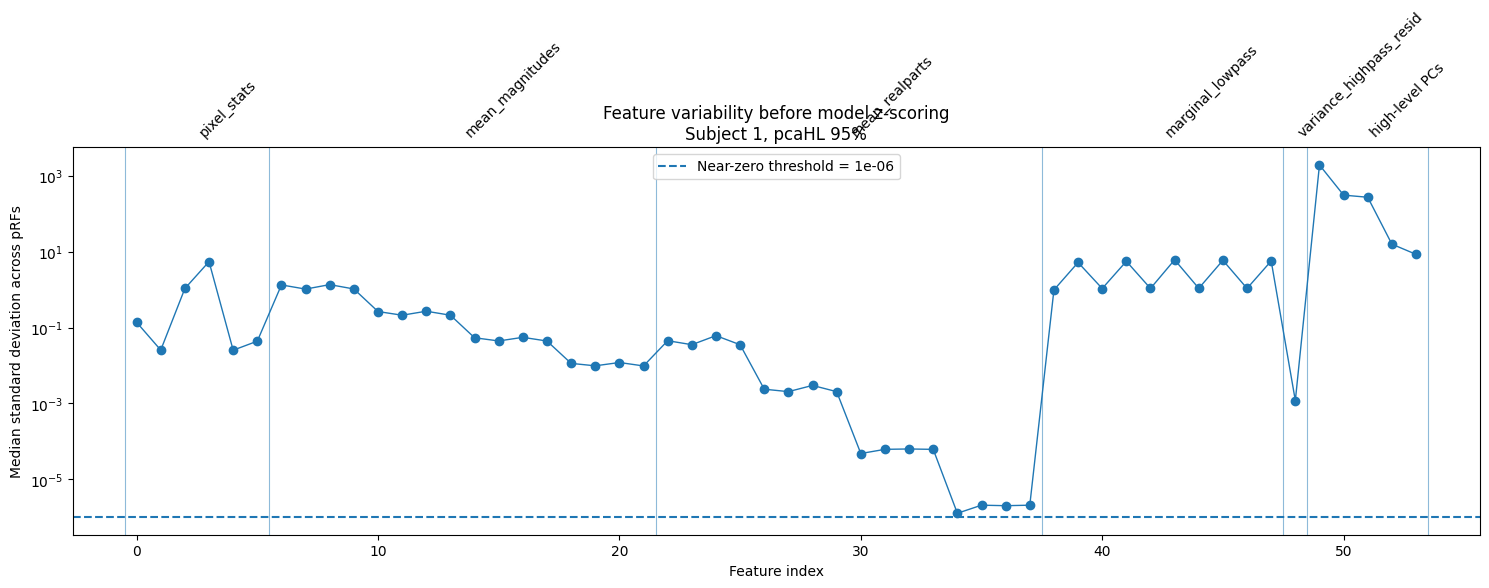

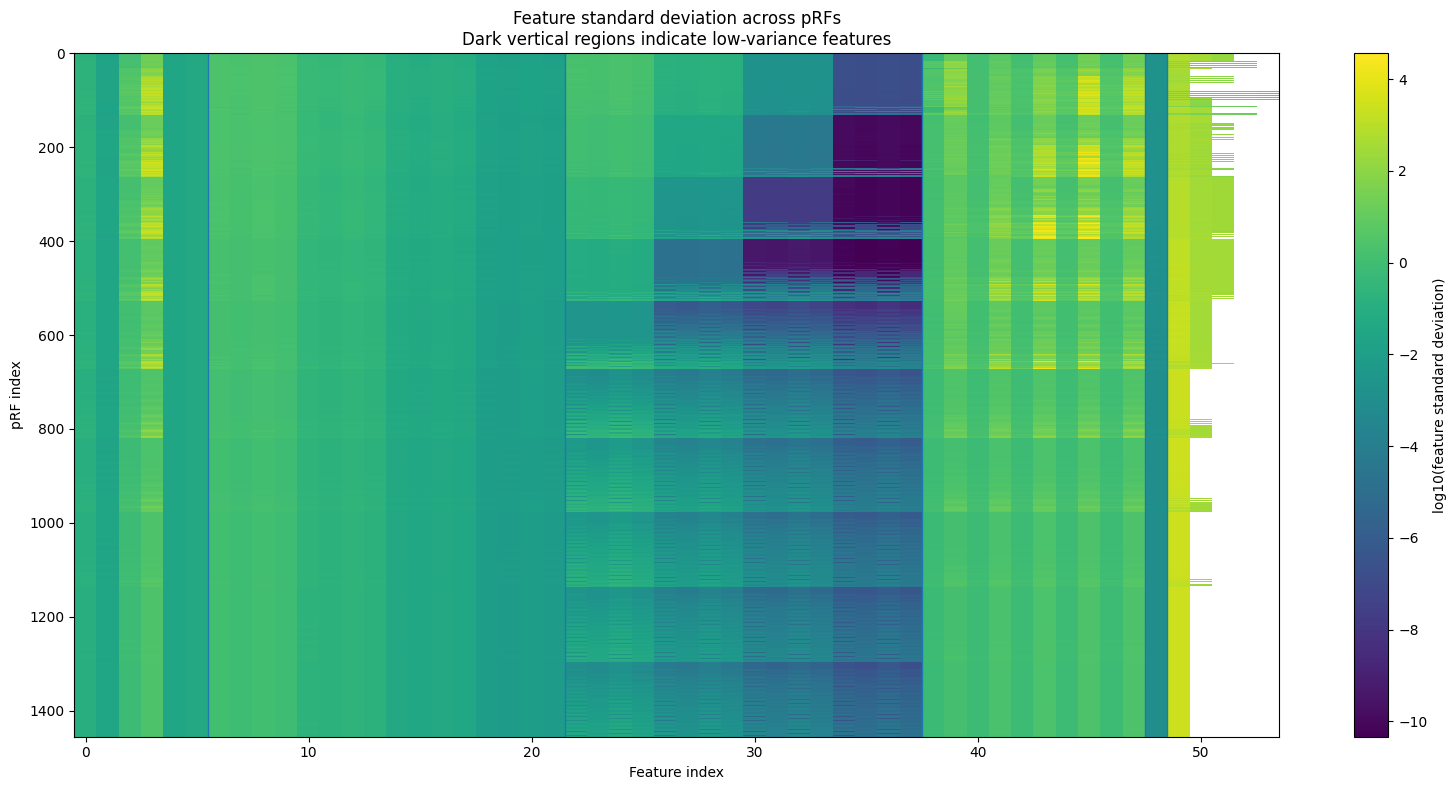

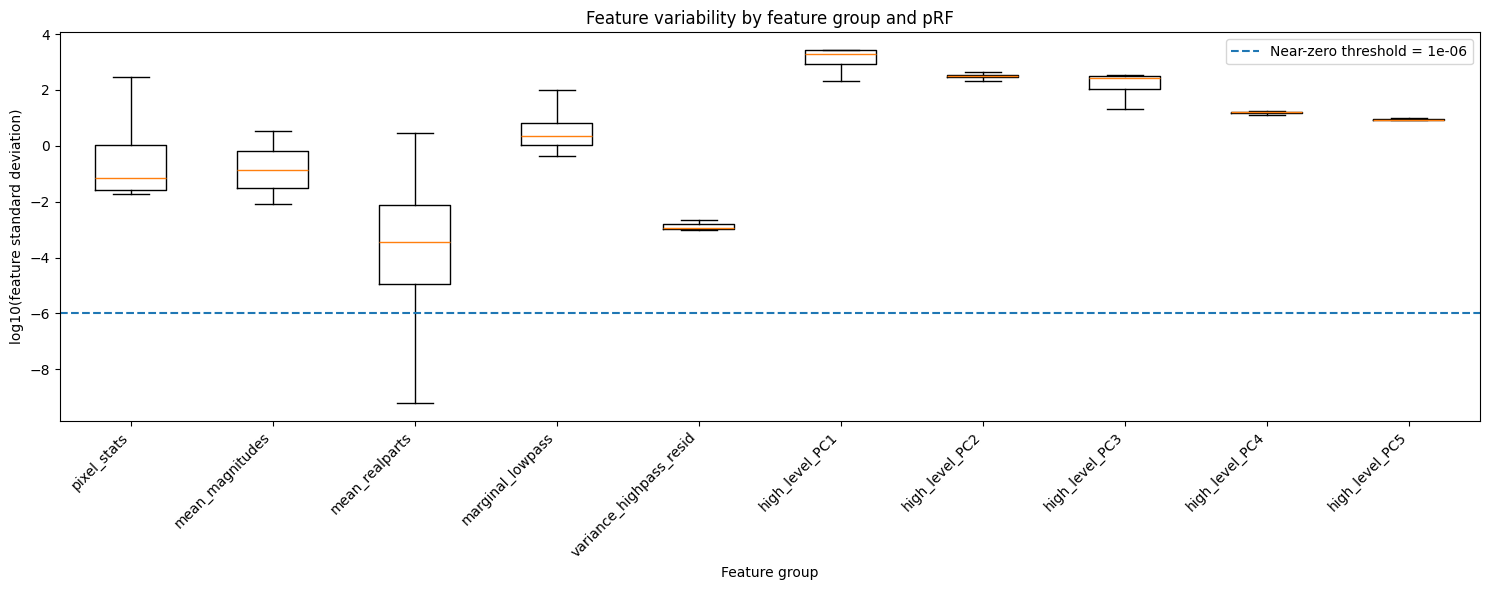


Near-zero variance summary:


,feature_group,number_of_values,near_zero_count,near_zero_fraction,median_std,minimum_std
0,pixel_stats,8736,0,0.000000,0.078495,1.914812e-02
1,mean_magnitudes,23296,0,0.000000,0.140138,7.951737e-03
2,mean_realparts,23296,3659,0.157066,0.000372,4.527309e-11
3,marginal_lowpass,14560,0,0.000000,2.167263,4.464265e-01
4,variance_highpass_resid,1456,0,0.000000,0.001184,9.884634e-04
5,high_level_PC1,1456,0,0.000000,1945.310774,4.553763e+01
6,high_level_PC2,1456,0,0.000000,311.479126,1.880211e+01
7,high_level_PC3,1456,0,0.000000,273.711647,1.270001e+01
8,high_level_PC4,1456,0,0.000000,15.859142,1.109934e+01
9,high_level_PC5,1456,0,0.000000,8.545524,8.307132e+00


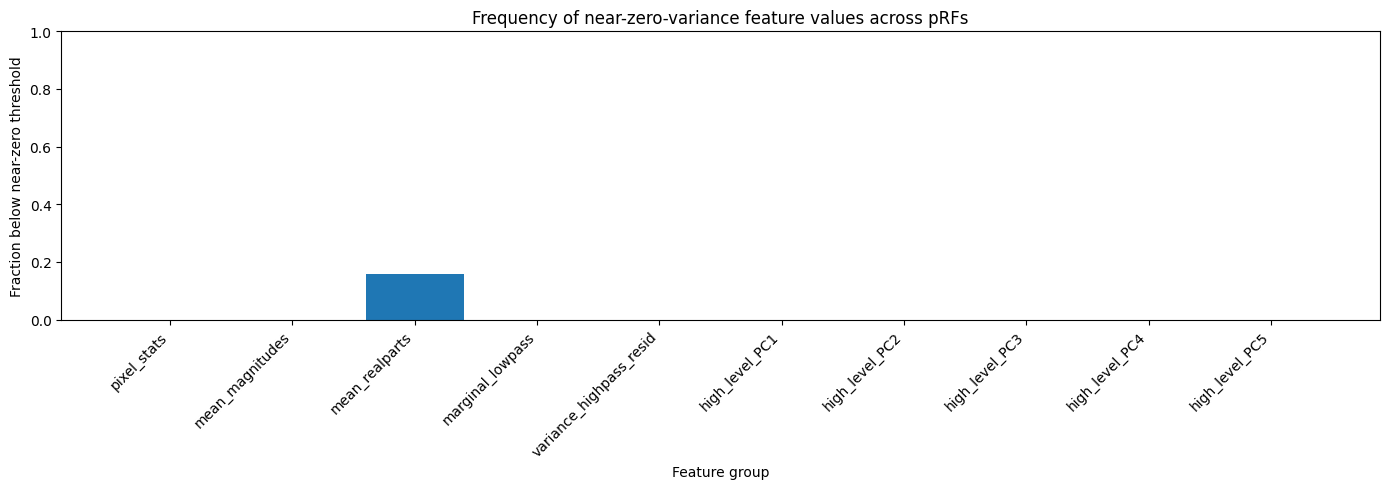


Mean-realpart features ordered by median standard deviation:


,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction
34,34,mean_realparts,low_level,0.000001,5.747094e-11,0.000522,1.596490e-12,682,0.468407
36,36,mean_realparts,low_level,0.000002,5.713053e-11,0.000796,4.017860e-12,624,0.428571
37,37,mean_realparts,low_level,0.000002,4.533809e-11,0.000391,4.254016e-12,650,0.446429
35,35,mean_realparts,low_level,0.000002,4.527309e-11,0.000392,4.259273e-12,650,0.446429
30,30,mean_realparts,low_level,0.000048,3.911168e-10,0.008671,2.266406e-09,260,0.178571
33,33,mean_realparts,low_level,0.000061,3.449954e-10,0.004930,3.751263e-09,239,0.164148
31,31,mean_realparts,low_level,0.000061,3.443477e-10,0.006542,3.766048e-09,238,0.163462
32,32,mean_realparts,low_level,0.000063,5.003543e-10,0.011008,3.936858e-09,254,0.174451
29,29,mean_realparts,low_level,0.002040,5.740370e-07,0.132517,4.160261e-06,20,0.013736
27,27,mean_realparts,low_level,0.002041,5.933671e-07,0.132425,4.166631e-06,17,0.011676


In [ ]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# Configuration
# ============================================================

LABELS_FILE = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/"
    "S1_4ori_4sf_featurelabels_pcaHL_v95pct_grid5.npy"
)

FEATURE_FILE = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/"
    "S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py"
)

# Values below this standard deviation are treated as approximately constant.
NEAR_ZERO_STD_THRESHOLD = 1e-6

# Small constant used only for log plotting.
LOG_EPSILON = 1e-12


# ============================================================
# Load feature labels
# ============================================================

feature_info = np.load(
    LABELS_FILE,
    allow_pickle=True
).item()

feature_column_labels = np.asarray(
    feature_info["feature_column_labels"]
)

feature_type_names = np.asarray(
    feature_info["feature_type_names"]
)

n_features = len(feature_column_labels)

print("Number of feature columns:", n_features)
print("Feature types:", feature_type_names)


# ============================================================
# Construct detailed feature-group labels
# ============================================================

if n_features != 54:
    raise ValueError(
        f"Expected 54 feature columns for pcaHL 95%, "
        f"but found {n_features}."
    )

detailed_feature_names = np.empty(n_features, dtype=object)

detailed_feature_names[0:6] = "pixel_stats"
detailed_feature_names[6:22] = "mean_magnitudes"
detailed_feature_names[22:38] = "mean_realparts"
detailed_feature_names[38:48] = "marginal_lowpass"
detailed_feature_names[48] = "variance_highpass_resid"

for pc_index in range(5):
    detailed_feature_names[49 + pc_index] = (
        f"high_level_PC{pc_index + 1}"
    )

feature_table = pd.DataFrame({
    "feature_index": np.arange(n_features),
    "feature_group": detailed_feature_names,
    "feature_type": feature_type_names[feature_column_labels],
})

display(feature_table)


# ============================================================
# Inspect the HDF5 file and find the feature dataset
# ============================================================

def list_hdf5_datasets(h5_file):
    """Return all datasets in an HDF5 file."""

    datasets = []

    def visitor(name, obj):
        if isinstance(obj, h5py.Dataset):
            datasets.append({
                "name": name,
                "shape": obj.shape,
                "dtype": str(obj.dtype),
            })

    h5_file.visititems(visitor)
    return datasets


with h5py.File(FEATURE_FILE, "r") as h5_file:
    dataset_info = list_hdf5_datasets(h5_file)

dataset_table = pd.DataFrame(dataset_info)

print("\nDatasets found in feature file:")
display(dataset_table)


# Identify a 3D dataset containing the 54-feature axis.
candidate_datasets = [
    item
    for item in dataset_info
    if len(item["shape"]) == 3
    and n_features in item["shape"]
]

if len(candidate_datasets) == 0:
    raise ValueError(
        "Could not find a 3D dataset containing an axis of length 54."
    )

if len(candidate_datasets) > 1:
    print("\nMultiple candidate feature datasets were found:")
    display(pd.DataFrame(candidate_datasets))

    raise ValueError(
        "More than one possible feature dataset was found. "
        "Select the correct dataset name manually."
    )

feature_dataset_name = candidate_datasets[0]["name"]
feature_dataset_shape = candidate_datasets[0]["shape"]

print("\nSelected feature dataset:")
print("Name:", feature_dataset_name)
print("Shape:", feature_dataset_shape)


# ============================================================
# Determine axis order
# ============================================================

# Expected logical axes:
# image × feature × pRF
#
# But this code also handles other axis orders automatically.

feature_axis = feature_dataset_shape.index(n_features)

remaining_axes = [
    axis
    for axis in range(3)
    if axis != feature_axis
]

# The image axis will normally be the largest remaining axis.
image_axis = max(
    remaining_axes,
    key=lambda axis: feature_dataset_shape[axis]
)

prf_axis = [
    axis
    for axis in remaining_axes
    if axis != image_axis
][0]

print("\nDetected axes:")
print("Image axis:", image_axis)
print("Feature axis:", feature_axis)
print("pRF axis:", prf_axis)

n_images = feature_dataset_shape[image_axis]
n_prfs = feature_dataset_shape[prf_axis]

print("\nDetected dimensions:")
print("Images:", n_images)
print("Features:", n_features)
print("pRFs:", n_prfs)


# ============================================================
# Compute feature variance for each pRF
# ============================================================

# Output shape:
# n_prfs × n_features

feature_mean_by_prf = np.full(
    (n_prfs, n_features),
    np.nan,
    dtype=np.float64
)

feature_std_by_prf = np.full(
    (n_prfs, n_features),
    np.nan,
    dtype=np.float64
)

feature_min_by_prf = np.full(
    (n_prfs, n_features),
    np.nan,
    dtype=np.float64
)

feature_max_by_prf = np.full(
    (n_prfs, n_features),
    np.nan,
    dtype=np.float64
)


with h5py.File(FEATURE_FILE, "r") as h5_file:

    feature_dataset = h5_file[feature_dataset_name]

    for prf_index in range(n_prfs):

        # Build indexing expression for this pRF.
        indexer = [slice(None)] * 3
        indexer[prf_axis] = prf_index

        prf_features = np.asarray(
            feature_dataset[tuple(indexer)],
            dtype=np.float64
        )

        # After selecting one pRF, there are two axes left:
        # images and features.
        remaining_original_axes = [
            axis
            for axis in range(3)
            if axis != prf_axis
        ]

        reduced_feature_axis = remaining_original_axes.index(
            feature_axis
        )

        # Rearrange to images × features.
        if reduced_feature_axis == 0:
            prf_features = prf_features.T

        if prf_features.shape != (n_images, n_features):
            raise ValueError(
                f"Unexpected pRF feature shape: "
                f"{prf_features.shape}"
            )

        feature_mean_by_prf[prf_index] = np.nanmean(
            prf_features,
            axis=0
        )

        feature_std_by_prf[prf_index] = np.nanstd(
            prf_features,
            axis=0
        )

        feature_min_by_prf[prf_index] = np.nanmin(
            prf_features,
            axis=0
        )

        feature_max_by_prf[prf_index] = np.nanmax(
            prf_features,
            axis=0
        )

        if (
            prf_index == 0
            or (prf_index + 1) % 100 == 0
            or prf_index == n_prfs - 1
        ):
            print(
                f"Processed pRF "
                f"{prf_index + 1}/{n_prfs}"
            )


feature_variance_by_prf = feature_std_by_prf ** 2

print("\nFinished computing feature statistics.")
print("Std matrix shape:", feature_std_by_prf.shape)


# ============================================================
# Add summary statistics to the feature table
# ============================================================

feature_table["median_std_across_prfs"] = np.nanmedian(
    feature_std_by_prf,
    axis=0
)

feature_table["minimum_std_across_prfs"] = np.nanmin(
    feature_std_by_prf,
    axis=0
)

feature_table["maximum_std_across_prfs"] = np.nanmax(
    feature_std_by_prf,
    axis=0
)

feature_table["median_variance_across_prfs"] = np.nanmedian(
    feature_variance_by_prf,
    axis=0
)

feature_table["near_zero_prf_count"] = np.sum(
    feature_std_by_prf < NEAR_ZERO_STD_THRESHOLD,
    axis=0
)

feature_table["near_zero_prf_fraction"] = (
    feature_table["near_zero_prf_count"] / n_prfs
)

print("\nFeature-level variance summary:")
display(feature_table)


# ============================================================
# Plot 1: Median standard deviation for every feature
# ============================================================

group_ranges = [
    ("pixel_stats", 0, 6),
    ("mean_magnitudes", 6, 22),
    ("mean_realparts", 22, 38),
    ("marginal_lowpass", 38, 48),
    ("variance_highpass_resid", 48, 49),
    ("high-level PCs", 49, 54),
]

plt.figure(figsize=(15, 6))

plt.plot(
    feature_table["feature_index"],
    feature_table["median_std_across_prfs"],
    marker="o",
    linewidth=1
)

plt.axhline(
    NEAR_ZERO_STD_THRESHOLD,
    linestyle="--",
    label=f"Near-zero threshold = {NEAR_ZERO_STD_THRESHOLD:g}"
)

for group_name, start, stop in group_ranges:
    plt.axvline(
        start - 0.5,
        linewidth=0.8,
        alpha=0.5
    )

    midpoint = (start + stop - 1) / 2

    plt.text(
        midpoint,
        1.02,
        group_name,
        rotation=45,
        ha="left",
        va="bottom",
        transform=plt.gca().get_xaxis_transform()
    )

plt.axvline(
    n_features - 0.5,
    linewidth=0.8,
    alpha=0.5
)

plt.yscale("log")
plt.xlabel("Feature index")
plt.ylabel("Median standard deviation across pRFs")
plt.title(
    "Feature variability before model z-scoring\n"
    "Subject 1, pcaHL 95%"
)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Plot 2: pRF × feature heatmap
# ============================================================

log_std = np.log10(
    feature_std_by_prf + LOG_EPSILON
)

plt.figure(figsize=(16, 8))

image = plt.imshow(
    log_std,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(
    image,
    label="log10(feature standard deviation)"
)

for _, start, _ in group_ranges:
    if start > 0:
        plt.axvline(
            start - 0.5,
            linewidth=1
        )

plt.xlabel("Feature index")
plt.ylabel("pRF index")
plt.title(
    "Feature standard deviation across pRFs\n"
    "Dark vertical regions indicate low-variance features"
)
plt.tight_layout()
plt.show()


# ============================================================
# Plot 3: Distribution by detailed feature group
# ============================================================

long_rows = []

for prf_index in range(n_prfs):
    for feature_index in range(n_features):
        long_rows.append({
            "prf_index": prf_index,
            "feature_index": feature_index,
            "feature_group": detailed_feature_names[
                feature_index
            ],
            "std": feature_std_by_prf[
                prf_index,
                feature_index
            ],
        })

variance_long_df = pd.DataFrame(long_rows)

# Log standard deviation is easier to compare because the scale
# may span several orders of magnitude.
variance_long_df["log10_std"] = np.log10(
    variance_long_df["std"] + LOG_EPSILON
)

group_order = [
    "pixel_stats",
    "mean_magnitudes",
    "mean_realparts",
    "marginal_lowpass",
    "variance_highpass_resid",
    "high_level_PC1",
    "high_level_PC2",
    "high_level_PC3",
    "high_level_PC4",
    "high_level_PC5",
]

plot_data = [
    variance_long_df.loc[
        variance_long_df["feature_group"] == group,
        "log10_std"
    ].dropna().to_numpy()
    for group in group_order
]

plt.figure(figsize=(15, 6))

plt.boxplot(
    plot_data,
    tick_labels=group_order,
    showfliers=False
)

plt.axhline(
    np.log10(NEAR_ZERO_STD_THRESHOLD),
    linestyle="--",
    label=f"Near-zero threshold = {NEAR_ZERO_STD_THRESHOLD:g}"
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Feature group")
plt.ylabel("log10(feature standard deviation)")
plt.title(
    "Feature variability by feature group and pRF"
)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Plot 4: Near-zero variance fraction by feature group
# ============================================================

near_zero_summary = (
    variance_long_df
    .assign(
        near_zero=lambda df:
        df["std"] < NEAR_ZERO_STD_THRESHOLD
    )
    .groupby("feature_group", as_index=False)
    .agg(
        number_of_values=("near_zero", "size"),
        near_zero_count=("near_zero", "sum"),
        near_zero_fraction=("near_zero", "mean"),
        median_std=("std", "median"),
        minimum_std=("std", "min"),
    )
)

near_zero_summary["feature_group"] = pd.Categorical(
    near_zero_summary["feature_group"],
    categories=group_order,
    ordered=True
)

near_zero_summary = (
    near_zero_summary
    .sort_values("feature_group")
    .reset_index(drop=True)
)

print("\nNear-zero variance summary:")
display(near_zero_summary)

plt.figure(figsize=(14, 5))

plt.bar(
    near_zero_summary["feature_group"].astype(str),
    near_zero_summary["near_zero_fraction"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Feature group")
plt.ylabel("Fraction below near-zero threshold")
plt.title(
    "Frequency of near-zero-variance feature values across pRFs"
)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# ============================================================
# Specifically inspect mean_realparts
# ============================================================

mean_realparts_table = feature_table.loc[
    feature_table["feature_group"] == "mean_realparts"
].copy()

mean_realparts_table = mean_realparts_table.sort_values(
    "median_std_across_prfs"
)

print("\nMean-realpart features ordered by median standard deviation:")
display(mean_realparts_table)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Inspect dimensions before aligning arrays
# ============================================================

best_prf_index = np.asarray(best_prf_index).squeeze()
val_r2_prf_v1 = np.asarray(val_r2_prf_v1).squeeze()
voxel_idx_prf_v1 = np.asarray(voxel_idx_prf_v1).squeeze()

print("best_prf_index shape:", best_prf_index.shape)
print("val_r2_prf_v1 shape:", val_r2_prf_v1.shape)
print("voxel_idx_prf_v1 shape:", voxel_idx_prf_v1.shape)
print("feature_std_by_prf shape:", feature_std_by_prf.shape)

# ============================================================
# 2. Align best-pRF indices with the filtered V1 voxels
# ============================================================

if best_prf_index.size == val_r2_prf_v1.size:
    # best_prf_index is already filtered to pRF V1
    best_prf_index_prf_v1 = best_prf_index.copy()

elif best_prf_index.size == keep_prf_v1.size:
    # best_prf_index contains all fitted voxels
    best_prf_index_prf_v1 = best_prf_index[keep_prf_v1]

else:
    raise ValueError(
        "Could not align best_prf_index with the filtered V1 voxels.\n"
        f"best_prf_index size = {best_prf_index.size}\n"
        f"val_r2_prf_v1 size = {val_r2_prf_v1.size}\n"
        f"keep_prf_v1 size = {np.asarray(keep_prf_v1).size}"
    )

best_prf_index_prf_v1 = np.asarray(
    best_prf_index_prf_v1
).astype(int).squeeze()

print(
    "Aligned best-pRF shape:",
    best_prf_index_prf_v1.shape
)

print(
    "Selected pRF range:",
    best_prf_index_prf_v1.min(),
    "to",
    best_prf_index_prf_v1.max()
)

if best_prf_index_prf_v1.max() >= feature_std_by_prf.shape[0]:
    raise ValueError(
        "A selected pRF index is outside feature_std_by_prf. "
        "The pRF indices may be one-based rather than zero-based."
    )

best_prf_index shape: (2392,)
val_r2_prf_v1 shape: (1350,)
voxel_idx_prf_v1 shape: (1350,)
feature_std_by_prf shape: (1456, 54)
Aligned best-pRF shape: (1350,)
Selected pRF range: 0 to 1292


In [ ]:
# ============================================================
# 3. Select the worst voxels
# ============================================================

N_WORST = 20

valid_r2 = np.isfinite(val_r2_prf_v1)

valid_positions = np.flatnonzero(valid_r2)

worst_filtered_order = np.argsort(
    val_r2_prf_v1[valid_r2]
)[:N_WORST]

worst_positions = valid_positions[worst_filtered_order]

worst_r2 = val_r2_prf_v1[worst_positions]
worst_prfs = best_prf_index_prf_v1[worst_positions]
worst_voxel_indices = voxel_idx_prf_v1[worst_positions]

print("Worst positions:", worst_positions)
print("Worst R²:", worst_r2)
print("Selected pRFs:", worst_prfs)

Worst positions: [ 483  486  487  608  443  671  577  530  569  696  193  254  437  531
  482  322  747 1109  143  734]
Worst R²: [-1490890.9     -774883.4     -510977.44    -341599.1     -255831.81
  -243493.72    -133652.47    -118886.92     -96080.35     -90402.89
   -85268.51     -68797.29     -55696.176    -46728.062    -16083.018
   -10404.501     -6592.2295    -5683.496     -5587.8066    -4265.3604]
Selected pRFs: [391 391 391 389 391 389 527 391 527 389 228 228 391 391 391 228 233  58
  62 233]


In [ ]:
# ============================================================
# 4. Summarize mean_realparts variance for the worst voxels
# ============================================================

MEAN_REALPARTS_SLICE = slice(22, 38)

thresholds = [1e-4, 1e-5, 1e-6, 1e-7, 1e-8]

summary_rows = []

for position, voxel_index, r2, prf_index in zip(
    worst_positions,
    worst_voxel_indices,
    worst_r2,
    worst_prfs
):
    selected_prf_std = feature_std_by_prf[prf_index]

    mean_real_std = selected_prf_std[
        MEAN_REALPARTS_SLICE
    ]

    row = {
        "position_in_filtered_v1": int(position),
        "original_voxel_index": int(voxel_index),
        "val_r2": float(r2),
        "best_prf_index": int(prf_index),
        "min_std_all_features": float(
            np.nanmin(selected_prf_std)
        ),
        "median_mean_realparts_std": float(
            np.nanmedian(mean_real_std)
        ),
        "min_mean_realparts_std": float(
            np.nanmin(mean_real_std)
        ),
    }

    for threshold in thresholds:
        row[f"mean_realparts_below_{threshold:.0e}"] = int(
            np.sum(mean_real_std < threshold)
        )

    summary_rows.append(row)

worst_variance_summary = pd.DataFrame(summary_rows)

display(worst_variance_summary)

,position_in_filtered_v1,original_voxel_index,val_r2,best_prf_index,min_std_all_features,median_mean_realparts_std,min_mean_realparts_std,mean_realparts_below_1e-04,mean_realparts_below_1e-05,mean_realparts_below_1e-06,mean_realparts_below_1e-07,mean_realparts_below_1e-08
0,483,346074,-1.490891e+06,391,7.978566e-08,0.002811,7.978566e-08,4,2,1,1,0
1,486,346155,-7.748834e+05,391,7.978566e-08,0.002811,7.978566e-08,4,2,1,1,0
2,487,346156,-5.109774e+05,391,7.978566e-08,0.002811,7.978566e-08,4,2,1,1,0
3,608,371721,-3.415991e+05,389,6.612896e-08,0.002876,6.612896e-08,4,2,1,1,0
4,443,337606,-2.558318e+05,391,7.978566e-08,0.002811,7.978566e-08,4,2,1,1,0
5,671,380436,-2.434937e+05,389,6.612896e-08,0.002876,6.612896e-08,4,2,1,1,0
6,577,363254,-1.336525e+05,527,1.294056e-04,0.013524,1.294056e-04,0,0,0,0,0
7,530,354704,-1.188869e+05,391,7.978566e-08,0.002811,7.978566e-08,4,2,1,1,0
8,569,363171,-9.608035e+04,527,1.294056e-04,0.013524,1.294056e-04,0,0,0,0,0
9,696,380936,-9.040289e+04,389,6.612896e-08,0.002876,6.612896e-08,4,2,1,1,0


In [ ]:
# ============================================================
# 5. Detailed table for each catastrophic voxel
# ============================================================

for _, voxel_row in worst_variance_summary.iterrows():

    voxel_index = int(
        voxel_row["original_voxel_index"]
    )

    prf_index = int(
        voxel_row["best_prf_index"]
    )

    r2 = voxel_row["val_r2"]

    selected_std = feature_std_by_prf[prf_index]

    selected_feature_table = feature_table.copy()
    selected_feature_table["std"] = selected_std
    selected_feature_table["variance"] = selected_std ** 2
    selected_feature_table["below_1e-6"] = (
        selected_feature_table["std"] < 1e-6
    )

    print("\n" + "=" * 90)
    print(
        f"Voxel {voxel_index} | "
        f"R² = {r2:.6g} | "
        f"best pRF = {prf_index}"
    )
    print("=" * 90)

    display(
        selected_feature_table
        .sort_values("std")
        .head(20)
    )


Voxel 346074 | R² = -1.49089e+06 | best pRF = 391


,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction,std,variance,below_1e-6
36,36,mean_realparts,low_level,0.000002,5.713053e-11,0.000796,4.017860e-12,624,0.428571,7.978566e-08,6.365752e-15,True
32,32,mean_realparts,low_level,0.000063,5.003543e-10,0.011008,3.936858e-09,254,0.174451,4.998887e-06,2.498888e-11,False
35,35,mean_realparts,low_level,0.000002,4.527309e-11,0.000392,4.259273e-12,650,0.446429,5.773418e-05,3.333235e-09,False
37,37,mean_realparts,low_level,0.000002,4.533809e-11,0.000391,4.254016e-12,650,0.446429,5.787819e-05,3.349884e-09,False
34,34,mean_realparts,low_level,0.000001,5.747094e-11,0.000522,1.596490e-12,682,0.468407,1.580248e-04,2.497184e-08,False
31,31,mean_realparts,low_level,0.000061,3.443477e-10,0.006542,3.766048e-09,238,0.163462,9.418375e-04,8.870579e-07,False
33,33,mean_realparts,low_level,0.000061,3.449954e-10,0.004930,3.751263e-09,239,0.164148,9.420746e-04,8.875046e-07,False
48,48,variance_highpass_resid,low_level,0.001184,9.884634e-04,0.002179,1.402298e-06,0,0.000000,1.492258e-03,2.226835e-06,False
30,30,mean_realparts,low_level,0.000048,3.911168e-10,0.008671,2.266406e-09,260,0.178571,2.590503e-03,6.710708e-06,False
28,28,mean_realparts,low_level,0.002978,1.070585e-06,0.236888,8.866297e-06,0,0.000000,3.030922e-03,9.186488e-06,False



Voxel 346155 | R² = -774883 | best pRF = 391


,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction,std,variance,below_1e-6
36,36,mean_realparts,low_level,0.000002,5.713053e-11,0.000796,4.017860e-12,624,0.428571,7.978566e-08,6.365752e-15,True
32,32,mean_realparts,low_level,0.000063,5.003543e-10,0.011008,3.936858e-09,254,0.174451,4.998887e-06,2.498888e-11,False
35,35,mean_realparts,low_level,0.000002,4.527309e-11,0.000392,4.259273e-12,650,0.446429,5.773418e-05,3.333235e-09,False
37,37,mean_realparts,low_level,0.000002,4.533809e-11,0.000391,4.254016e-12,650,0.446429,5.787819e-05,3.349884e-09,False
34,34,mean_realparts,low_level,0.000001,5.747094e-11,0.000522,1.596490e-12,682,0.468407,1.580248e-04,2.497184e-08,False
31,31,mean_realparts,low_level,0.000061,3.443477e-10,0.006542,3.766048e-09,238,0.163462,9.418375e-04,8.870579e-07,False
33,33,mean_realparts,low_level,0.000061,3.449954e-10,0.004930,3.751263e-09,239,0.164148,9.420746e-04,8.875046e-07,False
48,48,variance_highpass_resid,low_level,0.001184,9.884634e-04,0.002179,1.402298e-06,0,0.000000,1.492258e-03,2.226835e-06,False
30,30,mean_realparts,low_level,0.000048,3.911168e-10,0.008671,2.266406e-09,260,0.178571,2.590503e-03,6.710708e-06,False
28,28,mean_realparts,low_level,0.002978,1.070585e-06,0.236888,8.866297e-06,0,0.000000,3.030922e-03,9.186488e-06,False



Voxel 346156 | R² = -510977 | best pRF = 391


...

,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction,std,variance,below_1e-6
37,37,mean_realparts,low_level,0.000002,4.533809e-11,0.000391,4.254016e-12,650,0.446429,1.687400e-07,2.847319e-14,True
35,35,mean_realparts,low_level,0.000002,4.527309e-11,0.000392,4.259273e-12,650,0.446429,1.691536e-07,2.861295e-14,True
34,34,mean_realparts,low_level,0.000001,5.747094e-11,0.000522,1.596490e-12,682,0.468407,1.933814e-07,3.739636e-14,True
36,36,mean_realparts,low_level,0.000002,5.713053e-11,0.000796,4.017860e-12,624,0.428571,2.022859e-07,4.091960e-14,True
33,33,mean_realparts,low_level,0.000061,3.449954e-10,0.004930,3.751263e-09,239,0.164148,1.773996e-03,3.147063e-06,False
31,31,mean_realparts,low_level,0.000061,3.443477e-10,0.006542,3.766048e-09,238,0.163462,1.793893e-03,3.218052e-06,False
30,30,mean_realparts,low_level,0.000048,3.911168e-10,0.008671,2.266406e-09,260,0.178571,2.010421e-03,4.041791e-06,False
48,48,variance_highpass_resid,low_level,0.001184,9.884634e-04,0.002179,1.402298e-06,0,0.000000,2.064503e-03,4.262172e-06,False
32,32,mean_realparts,low_level,0.000063,5.003543e-10,0.011008,3.936858e-09,254,0.174451,2.160186e-03,4.666402e-06,False
21,21,mean_magnitudes,low_level,0.009723,7.951737e-03,0.017827,9.452926e-05,0,0.000000,1.667956e-02,2.782076e-04,False



Voxel 302496 | R² = -5587.81 | best pRF = 62


,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction,std,variance,below_1e-6
37,37,mean_realparts,low_level,0.000002,4.533809e-11,0.000391,4.254016e-12,650,0.446429,1.695488e-07,2.874681e-14,True
35,35,mean_realparts,low_level,0.000002,4.527309e-11,0.000392,4.259273e-12,650,0.446429,1.696201e-07,2.877098e-14,True
34,34,mean_realparts,low_level,0.000001,5.747094e-11,0.000522,1.596490e-12,682,0.468407,1.943949e-07,3.778939e-14,True
36,36,mean_realparts,low_level,0.000002,5.713053e-11,0.000796,4.017860e-12,624,0.428571,2.050860e-07,4.206028e-14,True
31,31,mean_realparts,low_level,0.000061,3.443477e-10,0.006542,3.766048e-09,238,0.163462,1.790980e-03,3.207610e-06,False
33,33,mean_realparts,low_level,0.000061,3.449954e-10,0.004930,3.751263e-09,239,0.164148,1.804324e-03,3.255585e-06,False
30,30,mean_realparts,low_level,0.000048,3.911168e-10,0.008671,2.266406e-09,260,0.178571,2.080745e-03,4.329499e-06,False
48,48,variance_highpass_resid,low_level,0.001184,9.884634e-04,0.002179,1.402298e-06,0,0.000000,2.090268e-03,4.369220e-06,False
32,32,mean_realparts,low_level,0.000063,5.003543e-10,0.011008,3.936858e-09,254,0.174451,2.179979e-03,4.752307e-06,False
19,19,mean_magnitudes,low_level,0.009791,7.966826e-03,0.017683,9.586792e-05,0,0.000000,1.674749e-02,2.804783e-04,False



Voxel 389556 | R² = -4265.36 | best pRF = 233


,feature_index,feature_group,feature_type,median_std_across_prfs,minimum_std_across_prfs,maximum_std_across_prfs,median_variance_across_prfs,near_zero_prf_count,near_zero_prf_fraction,std,variance,below_1e-6
37,37,mean_realparts,low_level,0.000002,4.533809e-11,0.000391,4.254016e-12,650,0.446429,7.620228e-11,5.806788e-21,True
35,35,mean_realparts,low_level,0.000002,4.527309e-11,0.000392,4.259273e-12,650,0.446429,7.740071e-11,5.990871e-21,True
34,34,mean_realparts,low_level,0.000001,5.747094e-11,0.000522,1.596490e-12,682,0.468407,9.745511e-11,9.497498e-21,True
36,36,mean_realparts,low_level,0.000002,5.713053e-11,0.000796,4.017860e-12,624,0.428571,1.070288e-10,1.145517e-20,True
33,33,mean_realparts,low_level,0.000061,3.449954e-10,0.004930,3.751263e-09,239,0.164148,3.417364e-05,1.167838e-09,False
31,31,mean_realparts,low_level,0.000061,3.443477e-10,0.006542,3.766048e-09,238,0.163462,3.554465e-05,1.263422e-09,False
30,30,mean_realparts,low_level,0.000048,3.911168e-10,0.008671,2.266406e-09,260,0.178571,3.888821e-05,1.512293e-09,False
32,32,mean_realparts,low_level,0.000063,5.003543e-10,0.011008,3.936858e-09,254,0.174451,4.412486e-05,1.947003e-09,False
48,48,variance_highpass_resid,low_level,0.001184,9.884634e-04,0.002179,1.402298e-06,0,0.000000,1.813931e-03,3.290345e-06,False
21,21,mean_magnitudes,low_level,0.009723,7.951737e-03,0.017827,9.452926e-05,0,0.000000,1.511444e-02,2.284462e-04,False


In [ ]:
drive.flush_and_unmount()